## 🧮 Interactive K-Means Clustering Demo (K = 2)

### 📌 Instructions:
- Click **"Step"** to advance through the K-Means algorithm.
- Click **"Reset"** to restart with new random initial centroids.
- Observe cluster assignments, centroid movements, and distance calculations.

---
### 🔁 Algorithm Steps:
1. **Initialize**: Randomly select 2 initial centroids.
2. **Assign Points**: Calculate the distance from each point to both centroids. Assign each point to the cluster of the nearest centroid.
3. **Update Centroids**: Move each centroid to the average (mean) position of all points in its cluster.
4. **Repeat**: Alternate between steps 2 and 3 until convergence (or until you stop clicking).
---

### 🔁 K-Means Algorithm (K = 2)

Given a dataset of $ n = 10 $ points $ \{ \mathbf{x}_1, \mathbf{x}_2, \dots, \mathbf{x}_n \} $ where each $ \mathbf{x}_i \in \mathbb{R}^2 $, K-Means alternates between two steps:

#### 1. **Assignment Step**  
Assign each point to the nearest centroid using **Euclidean distance**:

$$
\text{Assign } \mathbf{x}_i \text{ to cluster } C_k \text{ where }
k = \underset{j \in \{1,2\}}{\arg\min} \, \| \mathbf{x}_i - \boldsymbol{\mu}_j \|_2
$$

The **Euclidean distance** between point $ \mathbf{x}_i = (x_i, y_i) $ and centroid $ \boldsymbol{\mu}_j = (\mu_{j,x}, \mu_{j,y}) $ is:

$$
\| \mathbf{x}_i - \boldsymbol{\mu}_j \|_2 = \sqrt{(x_i - \mu_{j,x})^2 + (y_i - \mu_{j,y})^2}
$$

> 💡 In the demo: Dashed lines show both distances; the smaller one determines cluster membership.

---

#### 2. **Update Step**  
Recompute each centroid as the **mean** of all points assigned to its cluster:

$$
\boldsymbol{\mu}_k^{\text{new}} = \frac{1}{|C_k|} \sum_{\mathbf{x}_i \in C_k} \mathbf{x}_i
$$

where:
- $ C_k $ = set of points assigned to cluster $ k $,
- $ |C_k| $ = number of points in cluster $ k $.

> 💡 In the demo: Centroids move to the geometric center of their assigned points.

---

### 🎨 Visual Guide:
- 🔴 **Red points**: Cluster 1  
- 🔵 **Blue points**: Cluster 2  
- ✖️ **'X' markers**: Centroids with coordinates labeled  
- ⬤ **Dashed lines**: Distances from a point to both centroids (only during assignment step)  
- 📏 **Numbers on lines**: Distance values (e.g., `2.34`)  
- 📦 **Bottom-left box**: Explanation of the current algorithmic step

---

### 📊 Data
- **10 random 2D points** uniformly sampled from $[1, 9] \times [1, 9]$
- **Fixed seed** (`np.random.seed(42)`) for reproducibility
- **K = 2 clusters**

In [ ]:
# @title
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import Button, HBox, Output
from IPython.display import display, clear_output

# Generate reproducible random data
# np.random.seed(42)
data = np.random.uniform(low=1, high=9, size=(10, 2))  # Keep points away from borders

class KMeansDemo:
    def __init__(self, data):
        self.data = data
        self.reset()

        # UI widgets
        self.step_btn = Button(description="Step", button_style='primary')
        self.reset_btn = Button(description="Reset", button_style='danger')
        self.out = Output()

        self.step_btn.on_click(self.on_step)
        self.reset_btn.on_click(self.on_reset)

        display(HBox([self.step_btn, self.reset_btn]), self.out)
        self.plot("Initialization", "Selecting 2 random points as initial centroids.")

    def reset(self):
        idx = np.random.choice(len(self.data), size=2, replace=False)
        self.centroids = self.data[idx].copy().astype(float)
        self.assignments = np.zeros(len(self.data), dtype=int)
        self.step_count = 0

    def euclidean(self, a, b):
        return np.sqrt(np.sum((a - b) ** 2))

    def on_step(self, btn):
        if self.step_count % 2 == 0:
            # Assignment Step
            self.assign_points()
            title = "Step: Assign Points to Nearest Centroid"
            desc = (
                "For each point, compute Euclidean distance to both centroids.\n"
                "Assign the point to the cluster with the smaller distance.\n"
                "Distances are shown as dashed lines with numeric labels."
            )
        else:
            # Update Centroids
            self.update_centroids()
            title = "Step: Recompute Centroids"
            desc = (
                "For each cluster, compute the mean (average) of all assigned points.\n"
                "This mean becomes the new centroid location.\n"
                "Centroids move to the 'center of mass' of their cluster."
            )
        self.step_count += 1
        self.plot(title, desc)

    def on_reset(self, btn):
        self.reset()
        self.plot("Initialization", "Selecting 2 random points as initial centroids.")

    def assign_points(self):
        for i, pt in enumerate(self.data):
            d0 = self.euclidean(pt, self.centroids[0])
            d1 = self.euclidean(pt, self.centroids[1])
            self.assignments[i] = 0 if d0 < d1 else 1

    def update_centroids(self):
        for k in range(2):
            cluster_pts = self.data[self.assignments == k]
            if len(cluster_pts) > 0:
                self.centroids[k] = np.mean(cluster_pts, axis=0)

    def plot(self, title, description):
        with self.out:
            clear_output(wait=True)
            fig, ax = plt.subplots(figsize=(9, 7.5))
            colors = ['red', 'blue']

            # Plot data points
            for i, pt in enumerate(self.data):
                c = self.assignments[i]
                ax.scatter(pt[0], pt[1], c=colors[c], s=160, edgecolor='k', zorder=3)

            # Plot centroids
            for k in range(2):
                cx, cy = self.centroids[k]
                ax.scatter(cx, cy, c=colors[k], marker='x', s=600, linewidths=4, zorder=5)
                ax.text(cx + 0.15, cy + 0.15, f'C{k+1} ({cx:.2f}, {cy:.2f})',
                        fontsize=11, fontweight='bold', color=colors[k])

            # Draw distances during assignment steps
            if "Assign" in title:
                for i, pt in enumerate(self.data):
                    for k in range(2):
                        cx, cy = self.centroids[k]
                        ax.plot([pt[0], cx], [pt[1], cy],
                                color=colors[k], linestyle='--', linewidth=1, alpha=0.7)
                        mid_x = (pt[0] + cx) / 2
                        mid_y = (pt[1] + cy) / 2
                        dist = self.euclidean(pt, self.centroids[k])
                        ax.text(mid_x, mid_y, f"{dist:.2f}",
                                fontsize=8, color=colors[k], ha='center', va='bottom')

            # Add algorithm description box at BOTTOM-LEFT
            props = dict(boxstyle='round,pad=0.6', facecolor='lightyellow', alpha=0.9, edgecolor='gray')
            ax.text(0.02, 0.02, description,
                    transform=ax.transAxes,
                    fontsize=10,
                    verticalalignment='bottom',
                    horizontalalignment='left',
                    bbox=props,
                    linespacing=1.6)

            # Final touches
            ax.set_title(f'K-Means Clustering Demo\n{title}', fontsize=14, pad=15)
            ax.set_xlabel('X', fontsize=12)
            ax.set_ylabel('Y', fontsize=12)
            ax.grid(True, linestyle='--', alpha=0.5)
            ax.set_xlim(0, 10)
            ax.set_ylim(0, 10)
            ax.set_aspect('equal', adjustable='box')
            plt.tight_layout()
            plt.show()

# Launch the interactive demo
demo = KMeansDemo(data)

Output()

# 🧪 K-Means Clustering: Interactive Step-by-Step Demonstration

This notebook provides an **interactive visualization** of the K-Means clustering algorithm on 2D synthetic data. You can explore how K-Means works iteratively—from random centroid initialization to convergence—while comparing its output to the **true cluster labels**.

---

## 🎛️ How to Use

### 1. **Adjust the main controls at the bottom:**
- **`Clusters`**: Choose the number of clusters (2 to 10)
- **`Sample Size`**: Set the number of data points (100 to 1000)
- **`Show True Labels`**: ✅ Check to display the original cluster assignments (ground truth)
- **`Show K-Means Labels`**: ✅ Check to display the current K-Means clustering result
- **`Hide All Colors`**: ✅ Check to show **all points in grayscale** (overrides other color settings)

> 💡 **Tip**: Enable **both** label checkboxes to **compare true vs. predicted clusters** in the same plot! True labels appear as filled circles; K-Means labels appear as colored outlines.

### 2. **After adjusting parameters, use the `Step` slider:**
- **Step 0**: Shows random initial centroids
- **Step 1+**: Shows point assignment + updated centroids
- The algorithm stops automatically when centroids no longer move significantly

Each step visualizes:
- Data points colored by cluster (if enabled)
- Red "X" markers showing current centroid positions
- Grid and axis for spatial reference

---

## 🔍 What You’ll Observe

| Scenario | What to Look For |
|--------|------------------|
| **Low cluster separation** | K-Means may merge close clusters or split dense ones |
| **High `cluster_std`** (hard-coded in data gen) | Overlapping blobs challenge the algorithm |
| **Small `Sample Size`** | Noisier centroids; slower convergence |
| **True vs. K-Means labels** | Mismatches reveal limitations of K-Means (e.g., non-spherical clusters) |
| **Final step** | Centroids stabilize at cluster centers (local optimum) |

> ⚠️ **Note**: K-Means assumes clusters are **spherical and equally sized**. It may fail on irregular shapes or varying densities.

---

## 📦 Technical Details

- **Data**: Generated using `sklearn.datasets.make_blobs`
- **Algorithm**: Custom implementation tracking every iteration
- **Colors**:
  - True labels → `tab10` colormap
  - K-Means labels → `Set1`/`tab10` with outlines when both shown
  - Centroids → red "X"
- **Convergence**: Stops when centroid movement < `1e-4`

---

## ▶️ Ready to Explore?

Just **run the cell below** and start interacting! Try these experiments:

1. Set **Clusters = 3**, **Sample Size = 500**, and step through  
2. Enable **"Hide All Colors"** → see raw point cloud  
3. Compare **True vs. K-Means** for `Clusters = 4` with overlapping groups  
4. Watch how **initialization** affects the first few steps  

Happy clustering! 🌟

In [ ]:
# @title
# Install required packages
!pip install -q scikit-learn matplotlib ipywidgets

# Import libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from ipywidgets import interact, IntSlider, Checkbox, fixed
import warnings
warnings.filterwarnings("ignore")

# Set random seed for reproducibility
np.random.seed(42)

def kmeans_step_by_step(X, n_clusters, max_iters=20):
    """Run K-Means and return history of centroids and labels."""
    centroids = X[np.random.choice(X.shape[0], n_clusters, replace=False)]
    history = []

    for i in range(max_iters):
        # Compute distances and assign clusters
        distances = np.sqrt(((X - centroids[:, np.newaxis])**2).sum(axis=2))
        labels = np.argmin(distances, axis=0)
        history.append((centroids.copy(), labels.copy()))

        # Update centroids
        new_centroids = np.array([X[labels == k].mean(axis=0) for k in range(n_clusters)])

        # Check convergence
        if np.allclose(centroids, new_centroids, atol=1e-4):
            # Pad history if converged early (for consistent slider range)
            while len(history) < max_iters:
                history.append((centroids.copy(), labels.copy()))
            break

        centroids = new_centroids

    return history

def visualize_kmeans(
    history, step, X, true_labels, n_clusters,
    show_true_labels, show_kmeans_labels, hide_all_colors
):
    """Visualize with optional toggles."""
    plt.figure(figsize=(9, 7))

    # Determine coloring
    if hide_all_colors:
        # Show all points in gray
        plt.scatter(X[:, 0], X[:, 1], c='gray', s=30, alpha=0.7, label='Data Points')
        color_centroids = 'black'
    else:
        if show_true_labels and show_kmeans_labels:
            # Show both: true labels as colored circles, K-Means as colored 'o' with edge
            plt.scatter(X[:, 0], X[:, 1], c=true_labels, cmap='tab10', s=40, alpha=0.7,
                        label='True Labels', marker='o')
            kmeans_labels = history[step][1]
            plt.scatter(X[:, 0], X[:, 1], c=kmeans_labels, cmap='Set1', s=80,
                        alpha=0.0, edgecolors=plt.cm.Set1(kmeans_labels / max(1, n_clusters-1)),
                        linewidths=1.8, label='K-Means Labels')
        elif show_true_labels:
            plt.scatter(X[:, 0], X[:, 1], c=true_labels, cmap='tab10', s=50, alpha=0.8, label='True Labels')
            color_centroids = 'black'
        elif show_kmeans_labels:
            kmeans_labels = history[step][1]
            plt.scatter(X[:, 0], X[:, 1], c=kmeans_labels, cmap='tab10', s=50, alpha=0.8, label='K-Means Labels')
            color_centroids = 'red'
        else:
            # No labels shown, just points
            plt.scatter(X[:, 0], X[:, 1], c='gray', s=30, alpha=0.7, label='Data Points')
            color_centroids = 'black'

    # Plot centroids only if showing K-Means labels and not hiding colors
    if show_kmeans_labels and not hide_all_colors:
        centroids = history[step][0]
        plt.scatter(centroids[:, 0], centroids[:, 1],
                    c='red', marker='x', s=250, linewidths=4, label='Centroids')

    plt.title(f'K-Means Clustering – Step {step+1}', fontsize=14)
    plt.xlabel('Feature 1', fontsize=12)
    plt.ylabel('Feature 2', fontsize=12)
    plt.legend(loc='best')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.axis('equal')
    plt.tight_layout()
    plt.show()

def run_kmeans_demo(
    n_clusters=3,
    sample_size=300,
    show_true_labels=True,
    show_kmeans_labels=True,
    hide_all_colors=False
):
    """Generate data and run K-Means with interactive controls."""
    # Generate isotropic Gaussian blobs with true labels
    X, y_true = make_blobs(
        n_samples=sample_size,
        centers=n_clusters,
        cluster_std=1.8,
        center_box=(-12.0, 12.0),
        random_state=42
    )

    # Run K-Means and get full history
    history = kmeans_step_by_step(X, n_clusters)

    # Interactive step slider
    max_step = len(history) - 1
    interact(
        visualize_kmeans,
        history=fixed(history),
        step=IntSlider(min=0, max=max_step, value=0, description='Step:'),
        X=fixed(X),
        true_labels=fixed(y_true),
        n_clusters=fixed(n_clusters),
        show_true_labels=fixed(show_true_labels),
        show_kmeans_labels=fixed(show_kmeans_labels),
        hide_all_colors=fixed(hide_all_colors)
    )

# Main interactive widget with all controls
print("🔍 K-Means Clustering: Step-by-Step Visualization")
print("Adjust parameters → Then use 'Step' slider to animate")
interact(
    run_kmeans_demo,
    n_clusters=IntSlider(min=2, max=10, step=1, value=3, description='Clusters:'),
    sample_size=IntSlider(min=100, max=1000, step=50, value=300, description='Sample Size:'),
    show_true_labels=Checkbox(value=True, description='Show True Labels'),
    show_kmeans_labels=Checkbox(value=True, description='Show K-Means Labels'),
    hide_all_colors=Checkbox(value=False, description='Hide All Colors (Grayscale)')
);

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 15.4 MB/s eta 0:00:00
🔍 K-Means Clustering: Step-by-Step Visualization
Adjust parameters → Then use 'Step' slider to animate


interactive(children=(IntSlider(value=3, description='Clusters:', max=10, min=2), IntSlider(value=300, descrip…

# 📐 The Elbow Method for K-Means Clustering: Concept & Mathematics

K-means clustering is an unsupervised learning algorithm that partitions $ n $ data points into $ k $ clusters by minimizing the within-cluster variance. But how do we choose the **optimal number of clusters $ k $**? That’s where the **elbow method** comes in.

---

## 🔢 Mathematical Foundation

### 1. **K-Means Objective Function**

Given a dataset $ X = \{x_1, x_2, ..., x_n\} $, K-means seeks to find:
- $ k $ cluster centroids $ \{\mu_1, \mu_2, ..., \mu_k\} $
- An assignment of each point to a cluster

that **minimizes the total Within-Cluster Sum of Squares (WCSS)**:

$$
\text{WCSS}(k) = \sum_{i=1}^{k} \sum_{x \in C_i} \| x - \mu_i \|^2
$$

Where:
- $ C_i $ is the set of points in cluster $ i $
- $ \mu_i = \frac{1}{|C_i|} \sum_{x \in C_i} x $ is the centroid of cluster $ i $
- $ \| x - \mu_i \|^2 $ is the squared Euclidean distance between point $ x $ and centroid $ \mu_i $

This is also known as the **inertia** in scikit-learn.

---

### 2. **The Elbow Method Principle**

- Compute $ \text{WCSS}(k) $ for $ k = 1, 2, 3, ..., k_{\max} $
- Plot $ k $ (x-axis) vs. $ \text{WCSS}(k) $ (y-axis)

**Observation**:
- When $ k = 1 $: WCSS is very high (all points in one cluster)
- As $ k $ increases: WCSS decreases because clusters become tighter
- But after a certain $ k^* $, the **marginal gain** in reducing WCSS becomes small

The **optimal $ k $** is the "elbow" point — where the curve bends sharply.

> **Mathematically**, we look for the value $ k^* $ that maximizes the **rate of change** in WCSS:
>
> $$
> k^* = \arg\max_{k} \left( \text{WCSS}(k) - \text{WCSS}(k+1) \right)
> $$
>
> In practice, this is done **visually**.

---

## 📉 Why "Elbow"?

Imagine your arm bent at the elbow:
- The **upper arm** = steep drop in WCSS (each new cluster helps a lot)
- The **forearm** = shallow decline (adding clusters gives little improvement)
- The **joint** = optimal trade-off between model complexity and fit

---

## ⚠️ Limitations

- **Not always clear**: Some datasets have no obvious elbow (e.g., uniform data, overlapping clusters)
- **Assumes spherical clusters**: K-means (and thus WCSS) works best when clusters are round and equally sized
- **Sensitive to noise**: Outliers can inflate WCSS

> 💡 In such cases, consider alternatives like the **silhouette score** or **gap statistic**.

---

## 🖼️ In This Demo

- **Left plot**: $ \text{WCSS}(k) $ for $ k = 1 $ to $ 10 $
- **Right plot**: K-means clustering using the **true $ k $** (so you can verify the ground truth)
- Try adding **noise** or increasing **cluster spread** to see how the elbow degrades!

In [ ]:
# @title
# INSTALL & IMPORT
!pip install ipywidgets -q
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
import ipywidgets as widgets
from IPython.display import display, clear_output

# WIDGET OUTPUT HOLDER
output_widget = widgets.Output()

# PARAMETERS WIDGETS
n_samples_slider = widgets.IntSlider(value=300, min=50, max=1000, step=50, description='Sample Size:')
n_centers_slider = widgets.IntSlider(value=4, min=2, max=8, step=1, description='True Clusters:')
cluster_std_slider = widgets.FloatSlider(value=1.0, min=0.1, max=3.0, step=0.1, description='Cluster Spread:')
add_noise_checkbox = widgets.Checkbox(value=False, description='Add Noise')
generate_button = widgets.Button(description='Generate New Data', button_style='info')

def generate_data(n_samples=300, n_centers=4, cluster_std=1.0, add_noise=False):
    X, _ = make_blobs(
        n_samples=n_samples,
        centers=n_centers,
        cluster_std=cluster_std,
        random_state=np.random.randint(0, 10000)
    )
    if add_noise:
        X += np.random.uniform(-2, 2, size=X.shape)
    return X, n_centers

def calculate_wcss(X, max_k=10):
    wcss = []
    for k in range(1, max_k + 1):
        kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, max_iter=300, random_state=42)
        kmeans.fit(X)
        wcss.append(kmeans.inertia_)
    return wcss

def update_plot(_=None):
    with output_widget:
        clear_output(wait=True)

        # Get current params
        X, true_k = generate_data(
            n_samples=n_samples_slider.value,
            n_centers=n_centers_slider.value,
            cluster_std=cluster_std_slider.value,
            add_noise=add_noise_checkbox.value
        )

        wcss = calculate_wcss(X, max_k=10)

        # Create a FRESH figure each time (Colab-safe)
        plt.figure(figsize=(15, 6))

        # Elbow plot
        plt.subplot(1, 2, 1)
        plt.plot(range(1, 11), wcss, marker='o', linestyle='--', color='blue')
        plt.title('Elbow Method for Optimal k')
        plt.xlabel('Number of Clusters (k)')
        plt.ylabel('WCSS')
        plt.grid(True)

        # Cluster plot
        plt.subplot(1, 2, 2)
        kmeans = KMeans(n_clusters=true_k, random_state=42)
        labels = kmeans.fit_predict(X)
        plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', s=50, alpha=0.8)
        plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
                    c='red', marker='x', s=200, linewidths=3, label='Centroids')
        plt.title(f'K-Means Clustering (k={true_k})')
        plt.xlabel('Feature 1')
        plt.ylabel('Feature 2')
        plt.legend()

        plt.tight_layout()
        plt.show()

# INITIAL PLOT
update_plot()

# BUTTON CLICK HANDLER
generate_button.on_click(update_plot)

# LAYOUT
controls = widgets.VBox([
    widgets.HTML("<b>Configure synthetic dataset:</b>"),
    n_samples_slider,
    n_centers_slider,
    cluster_std_slider,
    add_noise_checkbox,
    generate_button
])

ui = widgets.HBox([controls, output_widget])

# INSTRUCTIONS
print("## 📊 Elbow Method Demo for K-Means Clustering")
print("\n✅ Adjust parameters and click 'Generate New Data'")
print("✅ The plot below will update in-place (no scrolling!)")
print("✅ Look for the 'elbow' point in the left graph to find optimal k\n")

display(ui)

## 📊 Elbow Method Demo for K-Means Clustering

✅ Adjust parameters and click 'Generate New Data'
✅ The plot below will update in-place (no scrolling!)
✅ Look for the 'elbow' point in the left graph to find optimal k



# 📊 Silhouette Analysis for Optimal Clustering

While the elbow method relies on within-cluster variance, **silhouette analysis** provides a more principled, interpretable way to evaluate clustering quality — especially when the elbow is ambiguous.

---

## 🔢 What is the Silhouette Score?

For each data point $ x_i $, the **silhouette coefficient** $ s(i) $ is defined as:

$$
s(i) = \frac{b(i) - a(i)}{\max\{a(i), b(i)\}}
$$

Where:
- $ a(i) $ = average distance from $ x_i $ to all other points **in the same cluster** (cohesion)
- $ b(i) $ = average distance from $ x_i $ to all points in the **nearest other cluster** (separation)

### 📌 Properties:
- $ s(i) \in [-1, 1] $
  - **Close to +1**: Well-clustered (far from other clusters, close to own)
  - **Close to 0**: On the boundary between clusters
  - **Close to -1**: Likely assigned to the wrong cluster

The **overall silhouette score** for a clustering is the **mean** of $ s(i) $ over all points.

---

## 📈 How to Use It for Choosing $ k $

1. For each candidate $ k = 2, 3, ..., k_{\max} $:
   - Run K-means
   - Compute the **average silhouette score**
2. Plot $ k $ vs. **average silhouette score**
3. Choose the $ k $ with the **highest score**

> ✅ Unlike WCSS (which always decreases), silhouette score **peaks** — making the optimal $ k $ clearer.

---

## ⚠️ Notes
- Silhouette score assumes **convex, isotropic clusters** (like K-means)
- It works best when clusters are **well-separated**
- **Never use $ k = 1 $** — silhouette is undefined (no "other cluster")

---

## 🖼️ In This Demo
- **Left**: Silhouette score vs. number of clusters ($ k = 2 $ to $ 10 $)
- **Right**: K-means clustering using the $ k $ with the **highest silhouette score**
- Try adding **noise** or increasing **cluster spread** to see how the score changes!

In [ ]:
# @title
# Install & import
!pip install ipywidgets scikit-learn -q
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_score
import ipywidgets as widgets
from IPython.display import display, clear_output

# Output widget
output_widget = widgets.Output()

# Controls
n_samples_slider = widgets.IntSlider(value=300, min=50, max=1000, step=50, description='Sample Size:')
n_centers_slider = widgets.IntSlider(value=4, min=2, max=8, step=1, description='True Clusters:')
cluster_std_slider = widgets.FloatSlider(value=1.0, min=0.1, max=3.0, step=0.1, description='Cluster Spread:')
add_noise_checkbox = widgets.Checkbox(value=False, description='Add Noise')
generate_button = widgets.Button(description='Generate New Data', button_style='success')

def generate_data(n_samples=300, n_centers=4, cluster_std=1.0, add_noise=False):
    X, _ = make_blobs(
        n_samples=n_samples,
        centers=n_centers,
        cluster_std=cluster_std,
        random_state=np.random.randint(0, 10000)
    )
    if add_noise:
        X += np.random.uniform(-2, 2, size=X.shape)
    return X

def compute_silhouette_scores(X, max_k=10):
    sil_scores = []
    k_vals = list(range(2, max_k + 1))  # silhouette undefined for k=1
    for k in k_vals:
        kmeans = KMeans(n_clusters=k, random_state=42)
        labels = kmeans.fit_predict(X)
        score = silhouette_score(X, labels)
        sil_scores.append(score)
    return k_vals, sil_scores

def plot_silhouette_and_clusters(X, k_vals, sil_scores):
    # Find best k
    best_idx = np.argmax(sil_scores)
    best_k = k_vals[best_idx]
    best_score = sil_scores[best_idx]

    # Fit best model
    kmeans_best = KMeans(n_clusters=best_k, random_state=42)
    labels_best = kmeans_best.fit_predict(X)

    # Plot
    plt.figure(figsize=(15, 6))

    # Silhouette plot
    plt.subplot(1, 2, 1)
    plt.plot(k_vals, sil_scores, marker='o', color='darkgreen', linewidth=2, markersize=7)
    plt.axvline(x=best_k, color='red', linestyle='--', alpha=0.7, label=f'Best k = {best_k}\n(score={best_score:.3f})')
    plt.title('Silhouette Score vs. Number of Clusters', fontsize=14)
    plt.xlabel('Number of Clusters (k)')
    plt.ylabel('Average Silhouette Score')
    plt.ylim(-0.1, 1.0)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend()

    # Cluster plot
    plt.subplot(1, 2, 2)
    scatter = plt.scatter(X[:, 0], X[:, 1], c=labels_best, cmap='tab10', s=60, alpha=0.8, edgecolor='k', linewidth=0.3)
    plt.scatter(kmeans_best.cluster_centers_[:, 0], kmeans_best.cluster_centers_[:, 1],
                c='red', marker='x', s=300, linewidths=4, label='Centroids')
    plt.title(f'K-Means Clustering (Best k = {best_k})', fontsize=14)
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.legend()

    plt.tight_layout()
    plt.show()

def update_plot(_=None):
    with output_widget:
        clear_output(wait=True)
        X = generate_data(
            n_samples=n_samples_slider.value,
            n_centers=n_centers_slider.value,
            cluster_std=cluster_std_slider.value,
            add_noise=add_noise_checkbox.value
        )
        k_vals, sil_scores = compute_silhouette_scores(X, max_k=10)
        plot_silhouette_and_clusters(X, k_vals, sil_scores)

# Initial plot
update_plot()

# Button
generate_button.on_click(update_plot)

# Layout
controls = widgets.VBox([
    widgets.HTML("<h4>Dataset Controls</h4>"),
    n_samples_slider,
    n_centers_slider,
    cluster_std_slider,
    add_noise_checkbox,
    generate_button
], layout=widgets.Layout(width="320px", padding="10px"))

ui = widgets.HBox([controls, output_widget], layout=widgets.Layout(align_items='flex-start'))
display(ui)

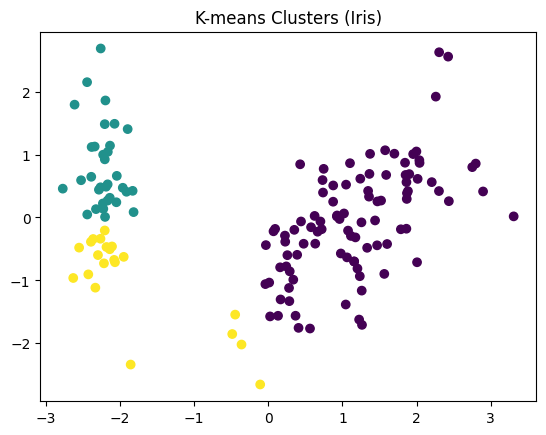

In [ ]:
from sklearn.cluster import KMeans
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Load data
iris = load_iris()
X = iris.data  # No y used!

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Fit K-means
kmeans = KMeans(n_clusters=3, random_state=42)
labels = kmeans.fit_predict(X_scaled)
# Step 1: Apply PCA to reduce to 2 components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Plot results (using first two PCA components for visualization)
plt.scatter(X_pca[:,0], X_pca[:,1], c=labels, cmap='viridis')
plt.title("K-means Clusters (Iris)")
plt.show()